# 2. Compréhension des données

Ce notebook examine les données NASA POWER et GPM IMERG téléchargées par `python -m donnees`, puis les extractions AppEEARS si elles sont disponibles. Les conclusions sont reprises dans `docs/02_data_understanding.md`.

In [1]:
import sys
sys.path.insert(0, "..")
import matplotlib.pyplot as plt
from donnees.config import charger
from moteur.series import series_lieux
config = charger()
series = series_lieux(config)
noms = {l["id"]: l["nom"] for l in config["lieux"]}

### 2.1 Complétude et unités

In [2]:
from donnees import power
from donnees.config import points
manquants = {}
for p in points(config):
    contenu = power.lire(p)
    for parametre, valeurs in contenu["properties"]["parameter"].items():
        manquants[parametre] = manquants.get(parametre, 0) + sum(v == power.VALEUR_MANQUANTE for v in valeurs.values())
print("Points", len(points(config)), "jours par point", power.jours_attendus(config))
print("Valeurs manquantes par paramètre", manquants)
print({k: v["units"] for k, v in contenu["parameters"].items()})

Points 18 jours par point 8766
Valeurs manquantes par paramètre {'IMERG_PRECTOT': 0, 'T2M_MAX': 0, 'T2M_MIN': 0, 'T2MDEW': 0, 'ALLSKY_SFC_SW_DWN': 0, 'WS2M': 0}
{'IMERG_PRECTOT': 'mm/day', 'T2M_MAX': 'C', 'T2M_MIN': 'C', 'T2MDEW': 'C', 'ALLSKY_SFC_SW_DWN': 'MJ/m^2/day', 'WS2M': 'm/s'}


**Constat**

Aucune valeur ne manque, et les unités sont celles qu'attend FAO 56.

### 2.2 Saisonnalité de la pluie

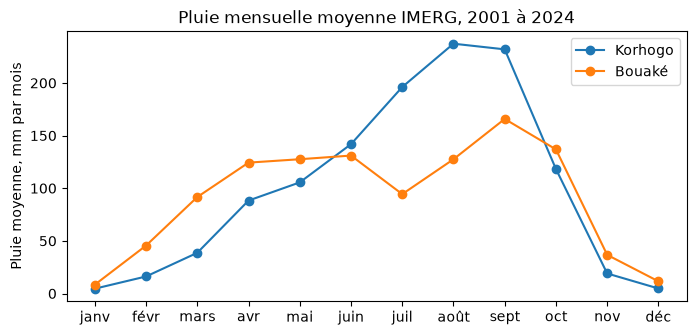

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for lieu, s in series.items():
    annees = len({j.year for j in s["jours"]})
    mensuel = [0.0] * 12
    for jour, pluie in zip(s["jours"], s["pluie"]):
        mensuel[jour.month - 1] += pluie / annees
    ax.plot(range(1, 13), mensuel, marker="o", label=noms[lieu])
ax.set_xticks(range(1, 13), ["janv", "févr", "mars", "avr", "mai", "juin", "juil", "août", "sept", "oct", "nov", "déc"])
ax.set_ylabel("Pluie moyenne, mm par mois")
ax.set_title("Pluie mensuelle moyenne IMERG, 2001 à 2024")
ax.legend(); plt.show()

**Constat**

Korhogo a une seule saison des pluies, avec un maximum en fin d'été. Bouaké montre une baisse en milieu d'année entre deux périodes plus humides, ce qui correspond à deux saisons.

**Analyse**

Le moteur ne traite que la première saison des pluies de Bouaké, ce qui est une limite.

### 2.3 Pluie annuelle

Korhogo moyenne 1202 mm, écart type 115 mm
Bouaké moyenne 1101 mm, écart type 172 mm


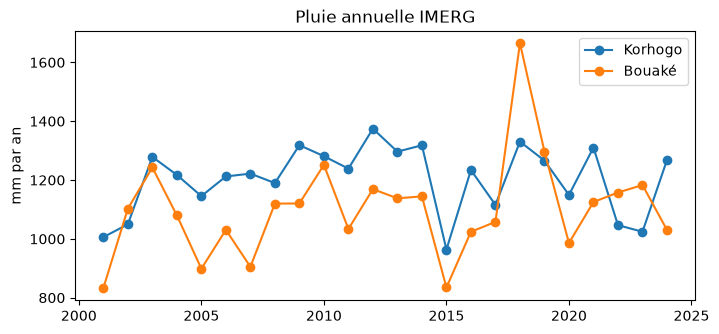

In [4]:
import statistics
fig, ax = plt.subplots(figsize=(8, 3.5))
for lieu, s in series.items():
    totaux = {}
    for jour, pluie in zip(s["jours"], s["pluie"]):
        totaux[jour.year] = totaux.get(jour.year, 0) + pluie
    ax.plot(list(totaux), list(totaux.values()), marker="o", label=noms[lieu])
    print(noms[lieu], "moyenne", round(statistics.mean(totaux.values())), "mm, écart type", round(statistics.stdev(totaux.values())), "mm")
ax.set_ylabel("mm par an"); ax.set_title("Pluie annuelle IMERG"); ax.legend(); plt.show()

**Constat**

D'après IMERG, Bouaké reçoit en moyenne moins de pluie que Korhogo, avec une variabilité plus forte. Bouaké n'est donc pas la zone plus humide.

### 2.4 Début des pluies et robustesse de sa tendance

Korhogo   7 jours,  14.4 jours par décennie, intervalle de   8.6 à  23.0


Korhogo  10 jours,   6.5 jours par décennie, intervalle de  -1.8 à  15.3


Korhogo  14 jours,   0.7 jours par décennie, intervalle de  -8.8 à  11.7
Bouaké    7 jours,   2.9 jours par décennie, intervalle de -12.1 à  19.8


Bouaké   10 jours,  -3.0 jours par décennie, intervalle de  -9.6 à   4.8
Bouaké   14 jours,  -5.3 jours par décennie, intervalle de -10.2 à   0.3


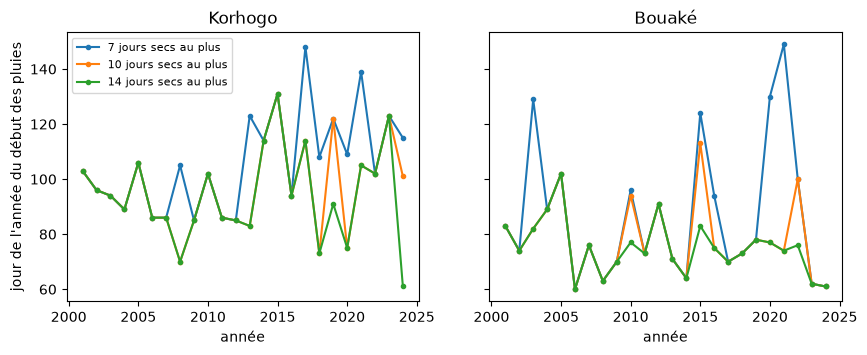

In [5]:
import copy
from moteur.criteres import debuts_par_annee
from moteur.statistiques import tendance
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, (lieu, s) in zip(axes, series.items()):
    for duree in [7, 10, 14]:
        variante = copy.deepcopy(config)
        variante["saison"]["sequence_seche_max_jours"] = duree
        debuts = {a: d.timetuple().tm_yday for a, d in debuts_par_annee(s, variante).items() if d}
        pente, bas, haut = tendance(list(debuts), list(debuts.values()))
        ax.plot(list(debuts), list(debuts.values()), marker=".", label=f"{duree} jours secs au plus")
        print(f"{noms[lieu]:8} {duree:2} jours, {pente:5.1f} jours par décennie, intervalle de {bas:5.1f} à {haut:5.1f}")
    ax.set_title(noms[lieu]); ax.set_xlabel("année")
axes[0].set_ylabel("jour de l'année du début des pluies"); axes[0].legend(fontsize=8); plt.show()

**Constat**

Avec 7 jours secs au plus, le début des pluies recule nettement à Korhogo. Ce recul disparaît avec 10 ou 14 jours.

**Analyse**

Le recul tient aux faux départs, des premières pluies suivies d'une longue séquence sèche, et dépend du critère choisi.

**Décision**

Une tendance n'est annoncée que si elle tient avec les trois critères. Aucune ne l'est.

### 2.5 Extractions AppEEARS

In [6]:
from donnees.lecture import resume_appeears
resume_appeears(config)

relief, pas encore disponible, relancer python -m donnees
occupation_sol, pas encore disponible, relancer python -m donnees
vegetation, pas encore disponible, relancer python -m donnees
humidite_sol, pas encore disponible, relancer python -m donnees
